# 使用Scikit-Learn 完成預測
### Scikit-Learn在三個面向提供支援。
1. 獲取資料:***klearn.datasets***
2. 掌握資料:***sklearn.preprocessing*** 
3. 機器學習:***sklearn Estimator API*** 

獲取資料的方式有很多種（包含檔案、資料庫、網路爬蟲、Kaggle Datasets等），<br>
其中最簡單的方式是從Sklearn import 內建的資料庫。由於其特性隨手可得且不用下載，所以我們通常叫他**玩具資料**：

# 基本架構

* 讀取資料&pre-processing
* 切分訓練集與測試集 
* 模型配適
* 預測 
* 評估(計算成績可能是誤差值或正確率或..)


In [ ]:
%matplotlib inline

from sklearn import datasets
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


## 讀取Iris資料集與資料前處理

Iris Flowers 資料集

我們在這個項目中使用 Iris Data Set，這個資料集中的每個樣本有4個特徵，1個類別。該資料集1中的樣本類別數為3類，每類樣本數目為50個，總共150個樣本。

屬性資訊：

    花萼長度 sepal length(cm)
    花萼寬度 sepal width(cm)
    花瓣長度 petal length(cm)
    花瓣寬度 petal width(cm)
    類別：
        Iris Setosa
        Iris Versicolour
        Iris Virginica

樣本特徵資料是數值型的，而且單位都相同（釐米）。

![Iris Flowers](images/iris_data.PNG)


In [ ]:
iris = datasets.load_iris()
print(iris.DESCR)

.. _iris_dataset:

Iris plants dataset
--------------------

**Data Set Characteristics:**

:Number of Instances: 150 (50 in each of three classes)
:Number of Attributes: 4 numeric, predictive attributes and the class
:Attribute Information:
    - sepal length in cm
    - sepal width in cm
    - petal length in cm
    - petal width in cm
    - class:
            - Iris-Setosa
            - Iris-Versicolour
            - Iris-Virginica

:Summary Statistics:

============== ==== ==== ======= ===== ====================
                Min  Max   Mean    SD   Class Correlation
============== ==== ==== ======= ===== ====================
sepal length:   4.3  7.9   5.84   0.83    0.7826
sepal width:    2.0  4.4   3.05   0.43   -0.4194
petal length:   1.0  6.9   3.76   1.76    0.9490  (high!)
petal width:    0.1  2.5   1.20   0.76    0.9565  (high!)
============== ==== ==== ======= ===== ====================

:Missing Attribute Values: None
:Class Distribution: 33.3% for each of 3 classes.
:Cr

* 印出iris的key值與檔案位置
* 查看前10筆資料
* 查看資料型別
* 印出標註的樣本類別資料

In [ ]:
print(iris.keys())                 # iris 的 key 值
print(iris['filename'])            # 檔案位置
print(iris['data'][:10])           # 前 10 筆資料
print(type(iris['data']))          # 資料型別
print(iris['target'])              # 標註的樣本類別
iris['feature_names'][:2]

dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module'])
iris.csv
[[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]
 [4.6 3.1 1.5 0.2]
 [5.  3.6 1.4 0.2]
 [5.4 3.9 1.7 0.4]
 [4.6 3.4 1.4 0.3]
 [5.  3.4 1.5 0.2]
 [4.4 2.9 1.4 0.2]
 [4.9 3.1 1.5 0.1]]
<class 'numpy.ndarray'>
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2]


['sepal length (cm)', 'sepal width (cm)']

In [ ]:
# we only take the first two features. 
data = iris['data'][:, :2]
print(data.shape)

(150, 2)


In [ ]:
#以下是組成 pandas DataFrame (也可以不用這種做)
x = pd.DataFrame(data, columns=iris['feature_names'][:2])   # 只取了 2 個特徵，欄位名稱也只取前 2 個
x.head(10)

,sepal length (cm),sepal width (cm)
0,5.1,3.5
1,4.9,3.0
2,4.7,3.2
3,4.6,3.1
4,5.0,3.6
5,5.4,3.9
6,4.6,3.4
7,5.0,3.4
8,4.4,2.9
9,4.9,3.1


In [ ]:
print(iris['data'].size)   # 150 筆 x 4 個特徵 = 600
print("target_names: " + str(iris['target_names']))

600
target_names: ['setosa' 'versicolor' 'virginica']


In [ ]:
#建立Target欄位與資料
y = pd.DataFrame(iris['target'], columns=['target'])
y.head()

,target
0,0
1,0
2,0
3,0
4,0


In [ ]:
#合併資料特徵欄位與目標欄位
x_all = pd.DataFrame(iris['data'], columns=iris['feature_names'])
iris_data = pd.concat([x_all[['sepal length (cm)', 'petal length (cm)']], y], axis=1)
iris_data.head(10)

,sepal length (cm),petal length (cm),target
0,5.1,1.4,0
1,4.9,1.4,0
2,4.7,1.3,0
3,4.6,1.5,0
4,5.0,1.4,0
5,5.4,1.7,0
6,4.6,1.4,0
7,5.0,1.5,0
8,4.4,1.4,0
9,4.9,1.5,0


In [ ]:
#只選擇目標為0與1的資料
iris_all = pd.concat([x_all, y], axis=1)
iris_data = iris_all[iris_all['target'].isin([0, 1])]
iris_data

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0
...,...,...,...,...,...
95,5.7,3.0,4.2,1.2,1
96,5.7,2.9,4.2,1.3,1
97,6.2,2.9,4.3,1.3,1
98,5.1,2.5,3.0,1.1,1


## 切分訓練集與測試集
> train_test_split()

In [ ]:
from sklearn.model_selection import train_test_split

X = iris_data[['sepal length (cm)', 'petal length (cm)']]
Y = iris_data['target']
# 70% 訓練、30% 測試
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.3)
print(X_train.shape, X_test.shape)

(70, 2) (30, 2)


In [ ]:
X_train.head()

,sepal length (cm),petal length (cm)
44,5.1,1.9
83,6.0,5.1
58,6.6,4.6
99,5.7,4.1
59,5.2,3.9


In [ ]:
X_test.head()

,sepal length (cm),petal length (cm)
41,4.5,1.3
26,5.0,1.6
51,6.4,4.5
55,5.7,4.5
96,5.7,4.2


# Appendix 

>normalization和standardization是差不多的<br>
都是把數據進行前處理，從而使數值都落入到統一的數值範圍，從而在建模過程中，各個特徵量沒差別對待。<br> 
* normalization一般是把數據限定在需要的範圍，比如一般都是【0，1】，從而消除了數據量綱對建模的影響。<br> 
* standardization 一般是指將數據正態化，使平均值0方差為1.<br> 

因此normalization和standardization 是針對數據而言的，消除一些數值差異帶來的特種重要性偏見。<br>
經過歸一化的數據，能加快訓練速度，促進算法的收斂。

### Standardization (z-score)
    to compute the mean and standard deviation on a training set so as to be able to later reapply the same transformation on the testing set. 

In [ ]:
# 新版 pandas 對 DataFrame 用 np.min 會回傳單一數字，所以改用 DataFrame 自己的方法，逐欄計算
def norm_stats(dfs):
    minimum = dfs.min()
    maximum = dfs.max()
    mu = dfs.mean()
    sigma = dfs.std(ddof=0)   # ddof=0 和 np.std、StandardScaler 的算法一致
    return (minimum, maximum, mu, sigma)


def z_score(col, stats):
    m, M, mu, s = stats
    df = pd.DataFrame()
    for c in col.columns:
        df[c] = (col[c]-mu[c])/s[c]
    return df

In [ ]:
stats = norm_stats(X_train)
arr_x_train = np.array(z_score(X_train, stats))
arr_y_train = np.array(y_train)
arr_x_train[:5]

array([[-0.59861334, -0.66523787],
       [ 0.792997  ,  1.57556336],
       [ 1.72073723,  1.22543817],
       [ 0.32912689,  0.87531298],
       [-0.44398997,  0.7352629 ]])

## use sklearn

In [ ]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler().fit(X_train)  #Compute the statistics to be used for later scaling.
print(sc.mean_)  #mean
print(sc.scale_) #standard deviation

[5.48714286 2.85      ]
[0.64673276 1.42806062]


In [ ]:
#transform: (x-u)/std.
X_train_std = sc.transform(X_train)
X_train_std[:5]

array([[-0.59861334, -0.66523787],
       [ 0.792997  ,  1.57556336],
       [ 1.72073723,  1.22543817],
       [ 0.32912689,  0.87531298],
       [-0.44398997,  0.7352629 ]])

The scaler instance can then be used on new data to transform it the same way it did on the training set:

In [ ]:
X_test_std = sc.transform(X_test)
print(X_test_std[:10])

[[-1.52635357 -1.0853881 ]
 [-0.75323671 -0.87531298]
 [ 1.41149049  1.15541313]
 [ 0.32912689  1.15541313]
 [ 0.32912689  0.94533802]
 [-1.68097694 -1.01536306]
 [-0.59861334 -0.94533802]
 [-0.13474322 -0.80528794]
 [-1.37173019 -0.94533802]
 [ 0.32912689  0.94533802]]


you can also use fit_transform method (i.e., fit and then transform)    

In [ ]:
X_train_std = sc.fit_transform(X_train)  
X_test_std = sc.fit_transform(X_test)
print(X_test_std[:10])


[[-1.51229886 -1.07598719]
 [-0.70213876 -0.87254424]
 [ 1.56630953  1.09407101]
 [ 0.43208539  1.09407101]
 [ 0.43208539  0.89062805]
 [-1.67433088 -1.00817287]
 [-0.54010674 -0.94035855]
 [-0.05401067 -0.80472992]
 [-1.35026684 -0.94035855]
 [ 0.43208539  0.89062805]]


In [ ]:
print('mean of X_train_std:',np.round(X_train_std.mean(),4))
print('std of X_train_std:',X_train_std.std())

mean of X_train_std: -0.0
std of X_train_std: 0.9999999999999999


## Min-Max Normaliaztion
    Transforms features by scaling each feature to a given range.
    The transformation is given by:

    X' = X - X.min(axis=0) / ((X.max(axis=0) - X.min(axis=0))
    X -> N 維資料
    


50.465308292651116
30.53746817250593


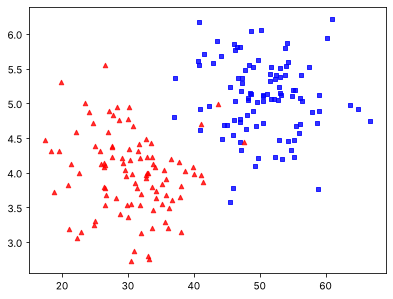

In [ ]:
x1 = np.random.normal(50, 6, 100)  # np.random.normal(mu,sigma,size))
y1 = np.random.normal(5, 0.5, 100)

x2 = np.random.normal(30,6,100)
y2 = np.random.normal(4,0.5,100)
plt.scatter(x1,y1,c='b',marker='s',s=20,alpha=0.8)
plt.scatter(x2,y2,c='r', marker='^', s=20, alpha=0.8)

print(np.sum(x1)/len(x1))
print(np.sum(x2)/len(x2))

In [ ]:
x_val = np.concatenate((x1,x2))
y_val = np.concatenate((y1,y2))

x_val.shape

(200,)

In [ ]:
def minmax_norm(X):
    return (X - X.min(axis=0)) / ((X.max(axis=0) - X.min(axis=0)))

In [ ]:
minmax_norm(x_val[:10])

array([0.        , 0.77089126, 0.59476216, 0.38659826, 1.        ,
       0.63286606, 0.65339577, 0.88536153, 0.24995566, 0.8415117 ])

In [ ]:
from sklearn.preprocessing import MinMaxScaler
x_val=x_val.reshape(-1, 1)
scaler = MinMaxScaler().fit(x_val)  # default range 0~1
print(scaler.data_max_)
print(scaler.transform(x_val)[:10])

[66.76644434]
[[0.39939661]
 [0.63373591]
 [0.58019532]
 [0.51691664]
 [0.70338151]
 [0.59177833]
 [0.59801905]
 [0.66853314]
 [0.47537935]
 [0.65520346]]
